<a href="https://colab.research.google.com/github/PK28102006/Parking_Utilization_DS_SAT2/blob/main/Parking_Utilization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving Parking_Utilization_Dataset.zip to Parking_Utilization_Dataset.zip


In [2]:
import zipfile
import os

zip_file = "Parking_Utilization_Dataset.zip"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("parking_data")

print("Dataset extracted successfully!")

print("\nFiles:")
for file in os.listdir("parking_data"):
    print(file)

Dataset extracted successfully!

Files:
calendar.csv
payments.csv
zones.csv
parking_utilization_combined.csv
parking_sessions.csv
README.txt
weather.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

In [4]:
file_path = "parking_data/parking_utilization_combined.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (3060, 18)


,session_id,zone,entry,exit,duration,fee,date,hour,location,capacity,zone_type,weekday,holiday,event,rain,temperature,payment_mode,amount
0,S00001,Z07,2026-03-07 16:28:00,2026-03-07 16:54:00,26,17.02,2026-03-07,16,College Road,110,Institutional,Saturday,True,Concert,No,29.4,UPI,17.02
1,S00002,Z04,2026-02-01 19:51:00,2026-02-01 20:49:00,58,32.91,2026-02-01,19,Railway Station,150,Transit,Sunday,True,NaN,No,34.3,UPI,32.91
2,S00003,Z07,2026-03-28 12:05:00,2026-03-28 13:55:00,110,54.72,2026-03-28,12,College Road,110,Institutional,Saturday,True,Concert,Yes,29.9,UPI,54.72
3,S00004,Z05,2026-03-04 20:06:00,2026-03-04 20:37:00,31,18.16,2026-03-04,20,Mall Area,180,Commercial,Wednesday,False,NaN,No,25.3,Cash,18.16
4,S00005,Z04,2026-03-27 10:36:00,2026-03-27 12:05:00,89,37.43,2026-03-27,10,Railway Station,150,Transit,Friday,False,NaN,No,33.0,Card,37.43


In [5]:
print("Number of records:", df.shape[0])
print("Number of attributes:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Number of records: 3060
Number of attributes: 18

Column Names:
['session_id', 'zone', 'entry', 'exit', 'duration', 'fee', 'date', 'hour', 'location', 'capacity', 'zone_type', 'weekday', 'holiday', 'event', 'rain', 'temperature', 'payment_mode', 'amount']


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3060 entries, 0 to 3059
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   session_id    3060 non-null   object 
 1   zone          3060 non-null   object 
 2   entry         3060 non-null   object 
 3   exit          3027 non-null   object 
 4   duration      3060 non-null   int64  
 5   fee           3060 non-null   float64
 6   date          3060 non-null   object 
 7   hour          3060 non-null   int64  
 8   location      3060 non-null   object 
 9   capacity      3060 non-null   int64  
 10  zone_type     3060 non-null   object 
 11  weekday       3060 non-null   object 
 12  holiday       3060 non-null   bool   
 13  event         618 non-null    object 
 14  rain          3060 non-null   object 
 15  temperature   3060 non-null   float64
 16  payment_mode  3060 non-null   object 
 17  amount        3060 non-null   float64
dtypes: bool(1), float64(3), int6

In [7]:
df.describe(include="all")

,session_id,zone,entry,exit,duration,fee,date,hour,location,capacity,zone_type,weekday,holiday,event,rain,temperature,payment_mode,amount
count,3060,3060,3060,3027,3060.000000,3060.000000,3060,3060.000000,3060,3060.000000,3060,3060,3060,618,3060,3060.00000,3060,3060.000000
unique,3000,8,2951,2919,NaN,NaN,90,NaN,8,NaN,4,7,2,4,2,NaN,4,NaN
top,S02107,Z05,2026-03-17 13:03:00,2026-02-23 18:34:00,NaN,NaN,2026-02-16,NaN,Mall Area,NaN,Commercial,Monday,False,Concert,No,NaN,UPI,NaN
freq,4,555,4,5,NaN,NaN,47,NaN,555,NaN,1342,497,2209,249,2249,NaN,1345,NaN
mean,NaN,NaN,NaN,NaN,99.411111,43.360820,NaN,14.168627,NaN,128.228758,NaN,NaN,NaN,NaN,NaN,29.90902,NaN,43.360820
std,NaN,NaN,NaN,NaN,65.806836,22.210558,NaN,4.057086,NaN,32.670204,NaN,NaN,NaN,NaN,NaN,3.62383,NaN,22.210558
min,NaN,NaN,NaN,NaN,-140.000000,12.550000,NaN,6.000000,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,23.00000,NaN,12.550000
25%,NaN,NaN,NaN,NaN,52.000000,27.220000,NaN,11.000000,NaN,100.000000,NaN,NaN,NaN,NaN,NaN,27.20000,NaN,27.220000
50%,NaN,NaN,NaN,NaN,85.000000,38.395000,NaN,14.000000,NaN,120.000000,NaN,NaN,NaN,NaN,NaN,29.90000,NaN,38.395000
75%,NaN,NaN,NaN,NaN,132.000000,53.912500,NaN,17.000000,NaN,150.000000,NaN,NaN,NaN,NaN,NaN,32.60000,NaN,53.912500


In [8]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0])

Missing Values:
exit       33
event    2442
dtype: int64


In [9]:
before = len(df)

df = df.drop_duplicates()

after = len(df)

print("Records before removing duplicates:", before)
print("Records after removing duplicates:", after)
print("Duplicates removed:", before - after)

Records before removing duplicates: 3060
Records after removing duplicates: 3009
Duplicates removed: 51


In [10]:
df["entry"] = pd.to_datetime(df["entry"], errors="coerce")
df["exit"] = pd.to_datetime(df["exit"], errors="coerce")
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print(df[["entry", "exit", "date"]].dtypes)

entry    datetime64[ns]
exit     datetime64[ns]
date     datetime64[ns]
dtype: object


In [11]:
print("Missing exit values before:",
      df["exit"].isnull().sum())

df.loc[df["exit"].isnull(), "exit"] = (
    df.loc[df["exit"].isnull(), "entry"] +
    pd.to_timedelta(
        df.loc[df["exit"].isnull(), "duration"].clip(lower=0),
        unit="m"
    )
)

print("Missing exit values after:",
      df["exit"].isnull().sum())

Missing exit values before: 30
Missing exit values after: 0


In [12]:
negative_count = (df["duration"] < 0).sum()

print("Negative duration records:", negative_count)

Negative duration records: 12


In [13]:
df = df[df["duration"] >= 0].copy()

print("Negative durations after cleaning:",
      (df["duration"] < 0).sum())

Negative durations after cleaning: 0


In [14]:
print("Unique zones:")
print(df["zone"].unique())

Unique zones:
['Z07' 'Z04' 'Z05' 'Z01' 'Z02' 'Z08' 'Z03' 'Z06']


In [15]:
print("Zone counts:")
print(df["zone"].value_counts())

Zone counts:
zone
Z05    544
Z04    519
Z01    481
Z02    376
Z03    296
Z08    277
Z07    260
Z06    244
Name: count, dtype: int64


In [16]:
print("Final dataset shape:", df.shape)

print("\nRemaining missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Final dataset shape: (2997, 18)

Remaining missing values:
event    2398
dtype: int64


In [17]:
cleaned_file = "parking_data/cleaned_parking_dataset.csv"

df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [18]:
df["hour"] = df["entry"].dt.hour

df[["entry", "hour"]].head()

,entry,hour
0,2026-03-07 16:28:00,16
1,2026-02-01 19:51:00,19
2,2026-03-28 12:05:00,12
3,2026-03-04 20:06:00,20
4,2026-03-27 10:36:00,10


In [19]:
zone_sessions = df.groupby("zone").size().sort_values(ascending=False)

print(zone_sessions)

zone
Z05    544
Z04    519
Z01    481
Z02    376
Z03    296
Z08    277
Z07    260
Z06    244
dtype: int64


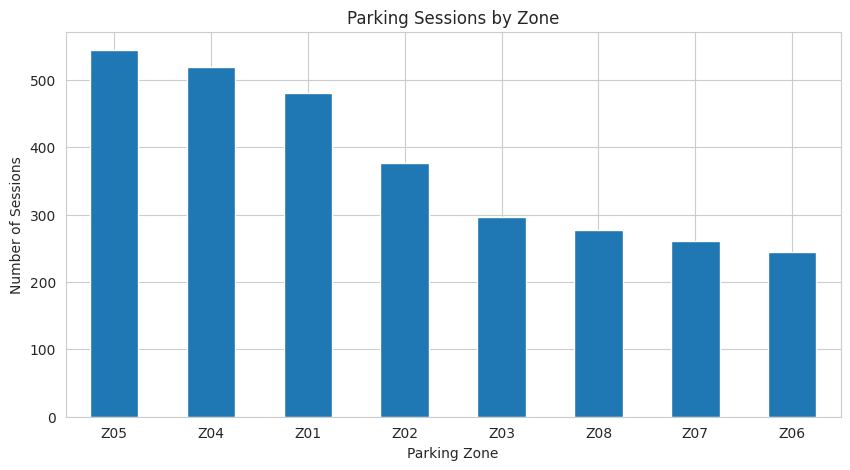

In [20]:
plt.figure(figsize=(10,5))

zone_sessions.plot(kind="bar")

plt.title("Parking Sessions by Zone")
plt.xlabel("Parking Zone")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)

plt.show()

In [21]:
hourly_sessions = df.groupby("hour").size()

print(hourly_sessions)

hour
6      74
7      77
8     115
9     165
10    150
11    215
12    297
13    273
14    255
15    219
16    216
17    219
18    202
19    179
20    151
21    102
22     88
dtype: int64


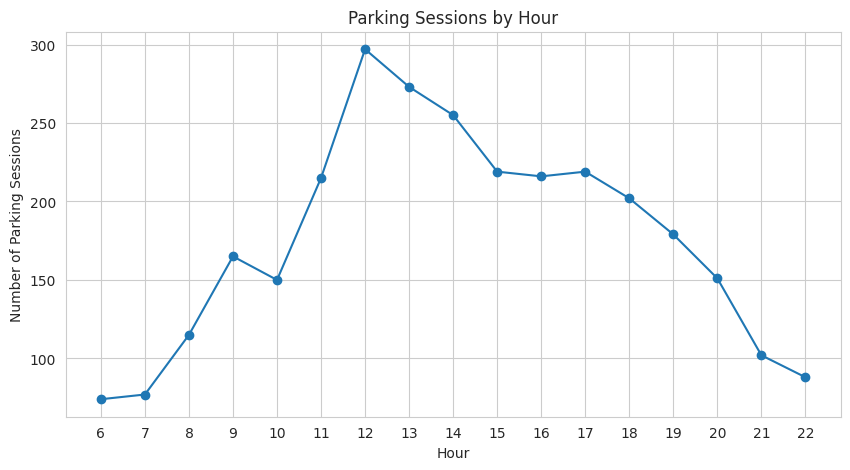

In [22]:
plt.figure(figsize=(10,5))

hourly_sessions.plot(kind="line", marker="o")

plt.title("Parking Sessions by Hour")
plt.xlabel("Hour")
plt.ylabel("Number of Parking Sessions")
plt.xticks(range(6,23))

plt.show()

In [23]:
peak_hour = hourly_sessions.idxmax()
peak_count = hourly_sessions.max()

print("Peak Parking Hour:", peak_hour)
print("Number of Sessions:", peak_count)

Peak Parking Hour: 12
Number of Sessions: 297


In [24]:
avg_duration_zone = (
    df.groupby("zone")["duration"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_duration_zone)

zone
Z01    106.800416
Z08    103.357401
Z03    103.293919
Z07    101.146154
Z05     98.351103
Z06     97.401639
Z04     96.759152
Z02     95.210106
Name: duration, dtype: float64


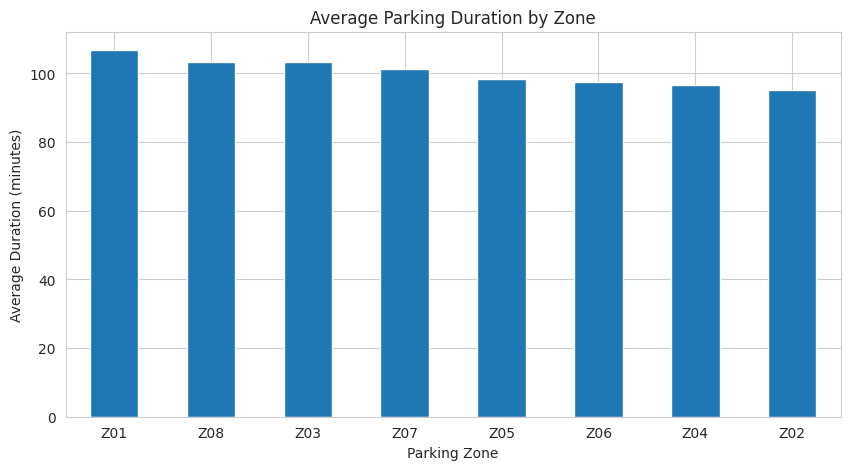

In [25]:
plt.figure(figsize=(10,5))

avg_duration_zone.plot(kind="bar")

plt.title("Average Parking Duration by Zone")
plt.xlabel("Parking Zone")
plt.ylabel("Average Duration (minutes)")
plt.xticks(rotation=0)

plt.show()

In [26]:
duration_type = (
    df.groupby("zone_type")["duration"]
    .mean()
    .sort_values(ascending=False)
)

print(duration_type)

zone_type
Residential      103.357401
Commercial       102.535201
Institutional     99.333333
Transit           96.108380
Name: duration, dtype: float64


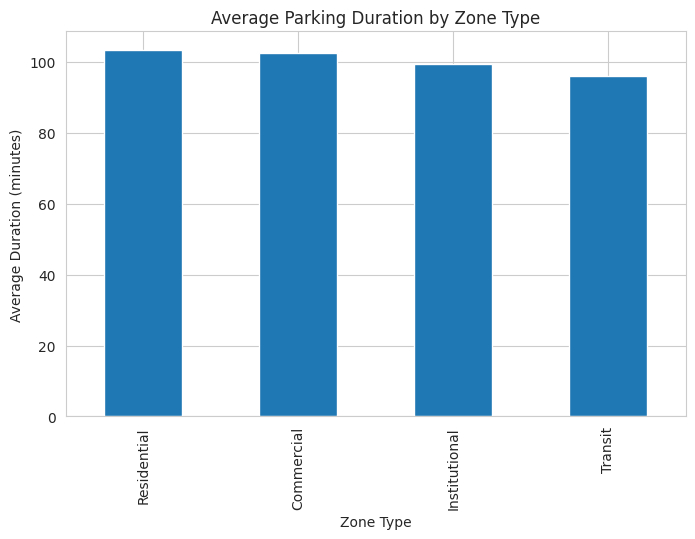

In [27]:
plt.figure(figsize=(8,5))

duration_type.plot(kind="bar")

plt.title("Average Parking Duration by Zone Type")
plt.xlabel("Zone Type")
plt.ylabel("Average Duration (minutes)")

plt.show()

In [28]:
event_usage = df.groupby("event").size().sort_values(ascending=False)

print(event_usage)

event
Concert         245
Market Event    153
Festival        130
Sports Event     71
dtype: int64


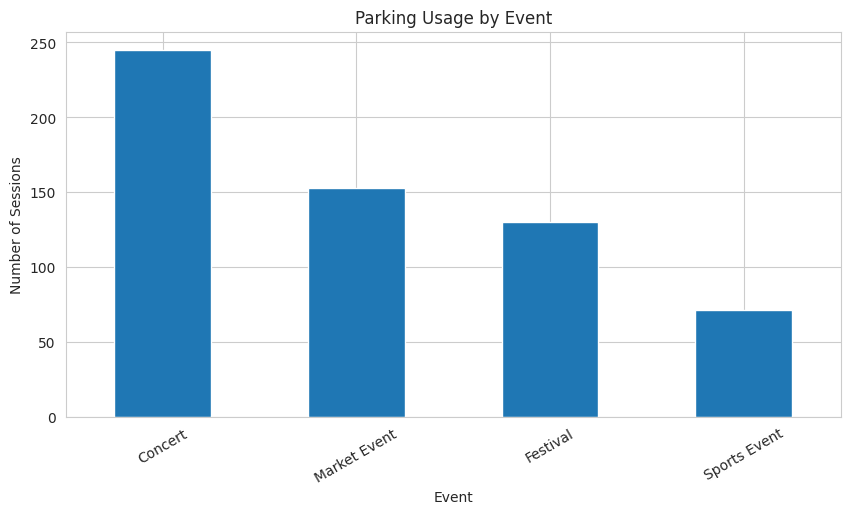

In [29]:
plt.figure(figsize=(10,5))

event_usage.plot(kind="bar")

plt.title("Parking Usage by Event")
plt.xlabel("Event")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=30)

plt.show()

In [30]:
rain_usage = df.groupby("rain").size()

print(rain_usage)

rain
No     2202
Yes     795
dtype: int64


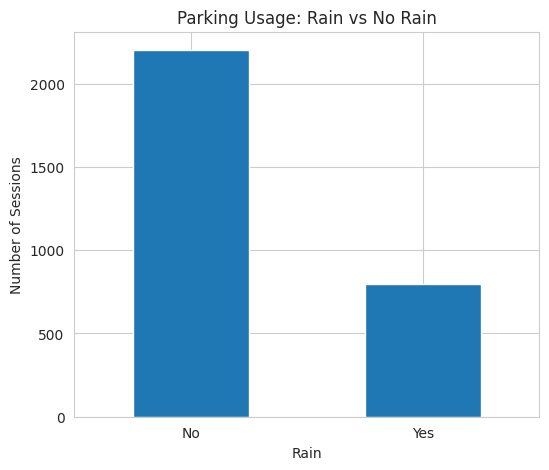

In [31]:
plt.figure(figsize=(6,5))

rain_usage.plot(kind="bar")

plt.title("Parking Usage: Rain vs No Rain")
plt.xlabel("Rain")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=0)

plt.show()

In [32]:
highest_zone = zone_sessions.idxmax()
highest_zone_count = zone_sessions.max()

lowest_zone = zone_sessions.idxmin()
lowest_zone_count = zone_sessions.min()

longest_zone = avg_duration_zone.idxmax()
longest_duration = avg_duration_zone.max()

print("========== EDA SUMMARY ==========")

print(f"Highest usage zone: {highest_zone}")
print(f"Sessions: {highest_zone_count}")

print(f"\nLowest usage zone: {lowest_zone}")
print(f"Sessions: {lowest_zone_count}")

print(f"\nPeak parking hour: {peak_hour}:00")
print(f"Peak sessions: {peak_count}")

print(f"\nLongest average parking duration zone: {longest_zone}")
print(f"Average duration: {longest_duration:.2f} minutes")

========== EDA SUMMARY ==========
Highest usage zone: Z05
Sessions: 544

Lowest usage zone: Z06
Sessions: 244

Peak parking hour: 12:00
Peak sessions: 297

Longest average parking duration zone: Z01
Average duration: 106.80 minutes


In [33]:
hourly = (
    df.groupby(["date", "hour", "zone"])
      .agg(
          occupancy=("session_id", "count"),
          avg_duration=("duration", "mean"),
          total_fee=("fee", "sum"),
          capacity=("capacity", "first"),
          location=("location", "first"),
          zone_type=("zone_type", "first"),
          weekday=("weekday", "first"),
          holiday=("holiday", "first"),
          event=("event", "first"),
          rain=("rain", "first"),
          temperature=("temperature", "first")
      )
      .reset_index()
)

hourly.head()

,date,hour,zone,occupancy,avg_duration,total_fee,capacity,location,zone_type,weekday,holiday,event,rain,temperature
0,2026-01-01,6,Z04,1,55.0,28.40,150,Railway Station,Transit,Thursday,False,Market Event,No,35.8
1,2026-01-01,6,Z07,1,72.0,28.28,110,College Road,Institutional,Thursday,False,Market Event,No,35.8
2,2026-01-01,8,Z04,1,182.0,71.14,150,Railway Station,Transit,Thursday,False,Market Event,No,35.8
3,2026-01-01,9,Z01,1,69.0,29.69,120,City Center,Commercial,Thursday,False,Market Event,No,35.8
4,2026-01-01,9,Z03,1,68.0,27.42,80,Market Road,Commercial,Thursday,False,Market Event,No,35.8


In [34]:
hourly["utilization_rate"] = (
    hourly["occupancy"] / hourly["capacity"]
)

hourly["utilization_rate"] = hourly["utilization_rate"].clip(0, 1)

hourly.head()

,date,hour,zone,occupancy,avg_duration,total_fee,capacity,location,zone_type,weekday,holiday,event,rain,temperature,utilization_rate
0,2026-01-01,6,Z04,1,55.0,28.40,150,Railway Station,Transit,Thursday,False,Market Event,No,35.8,0.006667
1,2026-01-01,6,Z07,1,72.0,28.28,110,College Road,Institutional,Thursday,False,Market Event,No,35.8,0.009091
2,2026-01-01,8,Z04,1,182.0,71.14,150,Railway Station,Transit,Thursday,False,Market Event,No,35.8,0.006667
3,2026-01-01,9,Z01,1,69.0,29.69,120,City Center,Commercial,Thursday,False,Market Event,No,35.8,0.008333
4,2026-01-01,9,Z03,1,68.0,27.42,80,Market Road,Commercial,Thursday,False,Market Event,No,35.8,0.012500


In [35]:
print("ML Dataset Shape:", hourly.shape)

hourly.info()

ML Dataset Shape: (2574, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2574 entries, 0 to 2573
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              2574 non-null   datetime64[ns]
 1   hour              2574 non-null   int32         
 2   zone              2574 non-null   object        
 3   occupancy         2574 non-null   int64         
 4   avg_duration      2574 non-null   float64       
 5   total_fee         2574 non-null   float64       
 6   capacity          2574 non-null   int64         
 7   location          2574 non-null   object        
 8   zone_type         2574 non-null   object        
 9   weekday           2574 non-null   object        
 10  holiday           2574 non-null   bool          
 11  event             510 non-null    object        
 12  rain              2574 non-null   object        
 13  temperature       2574 non-null   float64       


In [36]:
ml_data = pd.get_dummies(
    hourly,
    columns=["zone", "zone_type", "weekday", "event", "rain"],
    drop_first=True
)

print("Encoded dataset shape:", ml_data.shape)

Encoded dataset shape: (2574, 30)


In [37]:
target = "occupancy"

drop_columns = [
    "date",
    "location",
    "occupancy",
    "utilization_rate"
]

X = ml_data.drop(columns=drop_columns)
y = ml_data[target]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(target)

Features:
['hour', 'avg_duration', 'total_fee', 'capacity', 'holiday', 'temperature', 'zone_Z02', 'zone_Z03', 'zone_Z04', 'zone_Z05', 'zone_Z06', 'zone_Z07', 'zone_Z08', 'zone_type_Institutional', 'zone_type_Residential', 'zone_type_Transit', 'weekday_Monday', 'weekday_Saturday', 'weekday_Sunday', 'weekday_Thursday', 'weekday_Tuesday', 'weekday_Wednesday', 'event_Festival', 'event_Market Event', 'event_Sports Event', 'rain_Yes']

Target:
occupancy


In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 2059
Testing records: 515


In [39]:
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=10
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [40]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:10])

Predictions generated successfully!
[1.    1.    1.005 1.    1.    1.    1.    1.    1.    1.   ]


In [41]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("========== MODEL PERFORMANCE ==========")
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"R²   : {r2:.4f}")

========== MODEL PERFORMANCE ==========
RMSE : 0.10
MAE  : 0.02
R²   : 0.9459


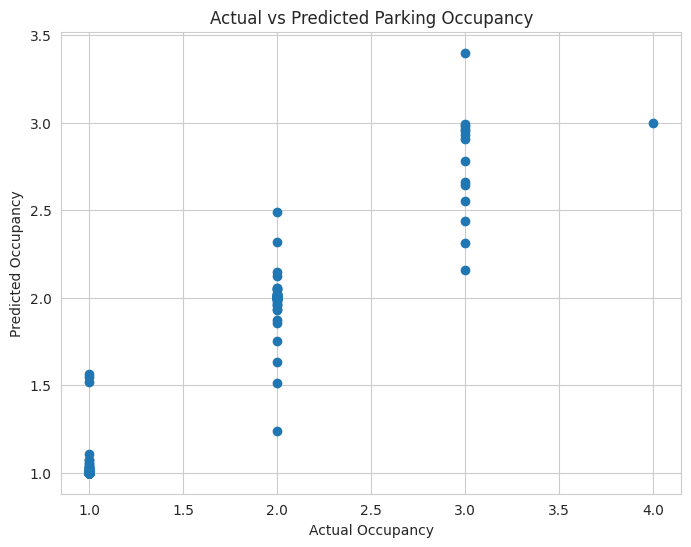

In [42]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Occupancy")
plt.ylabel("Predicted Occupancy")
plt.title("Actual vs Predicted Parking Occupancy")

plt.show()

In [43]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance.head(10))

avg_duration         0.503089
total_fee            0.490658
temperature          0.002013
hour                 0.000829
capacity             0.000653
weekday_Sunday       0.000348
zone_Z05             0.000268
holiday              0.000238
event_Festival       0.000231
weekday_Wednesday    0.000224
dtype: float64


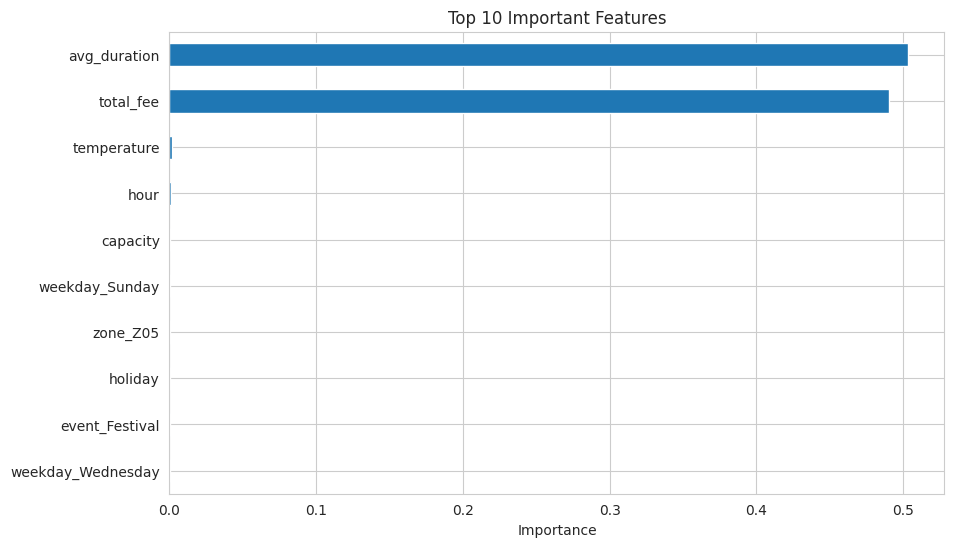

In [44]:
plt.figure(figsize=(10,6))

importance.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Important Features")
plt.xlabel("Importance")

plt.show()

In [45]:
hourly["demand_level"] = pd.cut(
    hourly["utilization_rate"],
    bins=[-0.01, 0.30, 0.70, 1.0],
    labels=["Low", "Medium", "High"]
)

print(hourly["demand_level"].value_counts())

demand_level
Low       2574
Medium       0
High         0
Name: count, dtype: int64


In [46]:
zone_utilization = (
    hourly.groupby("zone")["utilization_rate"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Utilization by Zone:")
print(zone_utilization)

Average Utilization by Zone:
zone
Z03    0.014122
Z06    0.011943
Z02    0.011824
Z01    0.009873
Z07    0.009767
Z04    0.008065
Z08    0.007851
Z05    0.006900
Name: utilization_rate, dtype: float64


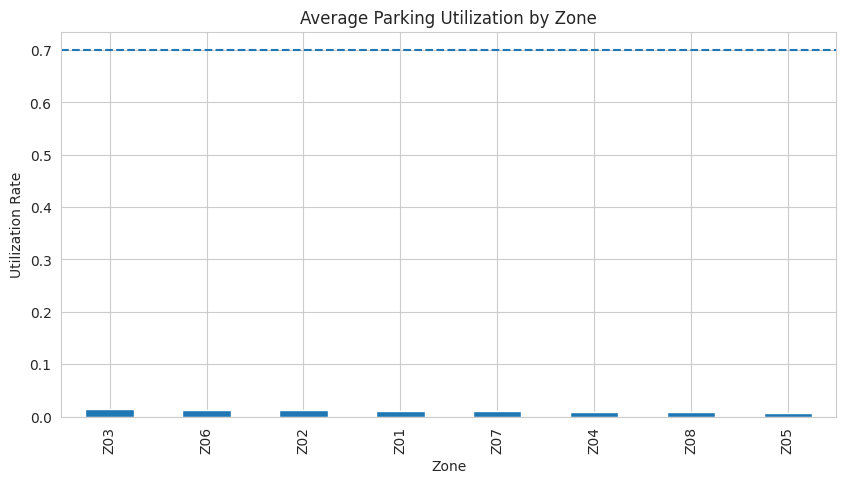

In [47]:
plt.figure(figsize=(10,5))

zone_utilization.plot(kind="bar")

plt.title("Average Parking Utilization by Zone")
plt.xlabel("Zone")
plt.ylabel("Utilization Rate")

plt.axhline(0.70, linestyle="--")

plt.show()

In [48]:
high_utilization_zones = zone_utilization[
    zone_utilization >= 0.70
]

low_utilization_zones = zone_utilization[
    zone_utilization < 0.30
]

print("HIGH UTILIZATION ZONES")
print(high_utilization_zones)

print("\nLOW UTILIZATION ZONES")
print(low_utilization_zones)

HIGH UTILIZATION ZONES
Series([], Name: utilization_rate, dtype: float64)

LOW UTILIZATION ZONES
zone
Z03    0.014122
Z06    0.011943
Z02    0.011824
Z01    0.009873
Z07    0.009767
Z04    0.008065
Z08    0.007851
Z05    0.006900
Name: utilization_rate, dtype: float64


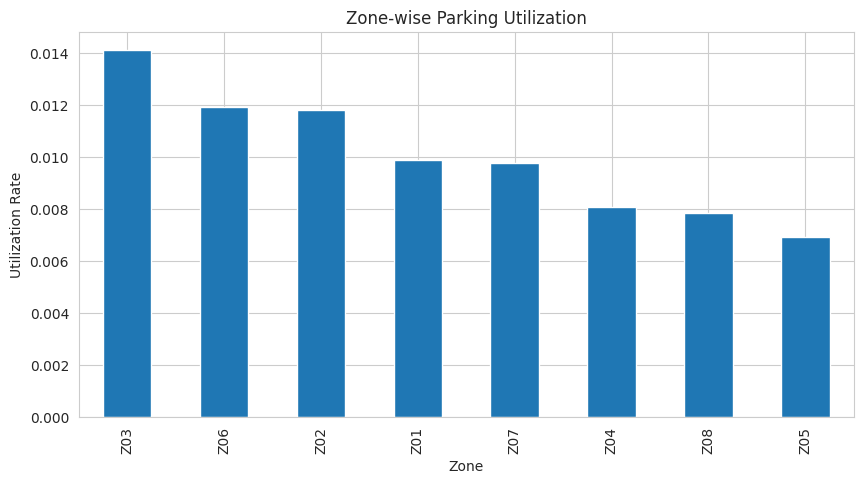

In [49]:
plt.figure(figsize=(10,5))

zone_utilization.plot(kind="bar")

plt.title("Zone-wise Parking Utilization")
plt.ylabel("Utilization Rate")
plt.xlabel("Zone")

plt.show()

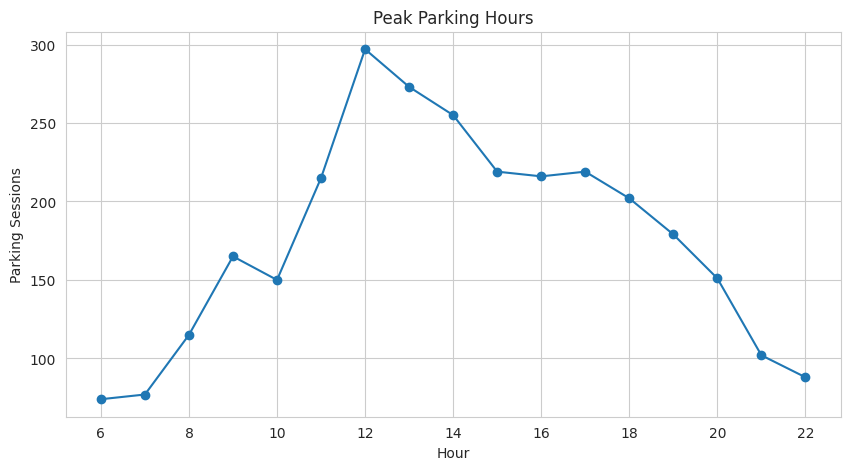

In [50]:
plt.figure(figsize=(10,5))

hourly_sessions.plot(kind="line", marker="o")

plt.title("Peak Parking Hours")
plt.xlabel("Hour")
plt.ylabel("Parking Sessions")

plt.show()

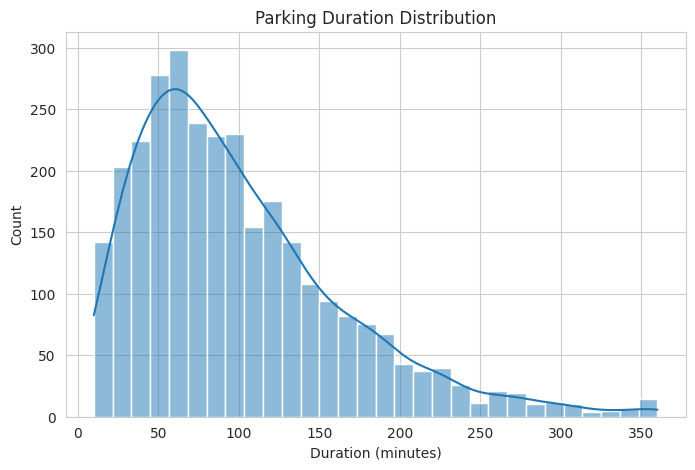

In [51]:
plt.figure(figsize=(8,5))

sns.histplot(df["duration"], bins=30, kde=True)

plt.title("Parking Duration Distribution")
plt.xlabel("Duration (minutes)")

plt.show()

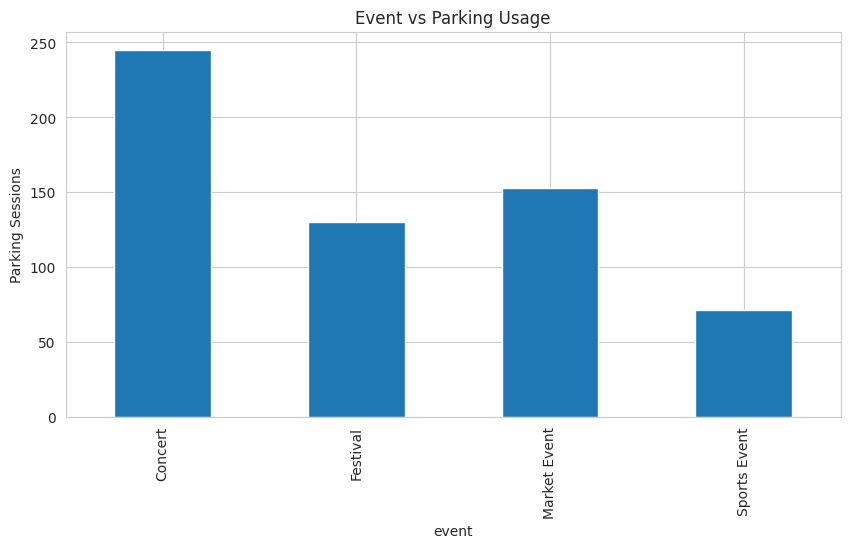

In [52]:
event_usage = df.groupby("event").size()

plt.figure(figsize=(10,5))

event_usage.plot(kind="bar")

plt.title("Event vs Parking Usage")
plt.ylabel("Parking Sessions")

plt.show()

In [53]:
print("========== KEY BUSINESS INSIGHTS ==========\n")

print(
    f"1. {highest_zone} has the highest parking activity "
    f"with {highest_zone_count} sessions."
)

print(
    f"2. The busiest parking period is around "
    f"{peak_hour}:00 with {peak_count} sessions."
)

print(
    f"3. {longest_zone} has the highest average parking duration "
    f"of {longest_duration:.2f} minutes."
)

print(
    f"4. Highest average utilization is observed in "
    f"{zone_utilization.idxmax()} "
    f"({zone_utilization.max()*100:.2f}%)."
)

========== KEY BUSINESS INSIGHTS ==========

1. Z05 has the highest parking activity with 544 sessions.
2. The busiest parking period is around 12:00 with 297 sessions.
3. Z01 has the highest average parking duration of 106.80 minutes.
4. Highest average utilization is observed in Z03 (1.41%).


## Recommendations

1. Increase parking management and monitoring in zones with
   consistently high utilization during peak hours.

2. Redirect drivers or provide incentives for low-utilization
   zones to improve overall parking capacity utilization.

3. Use peak-hour demand information to allocate parking resources
   more effectively.

4. Consider event and weather conditions when planning parking
   management strategies.

In [54]:
from google.colab import files

df.to_csv(
    "cleaned_parking_dataset.csv",
    index=False
)

files.download("cleaned_parking_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [55]:
excel_file = "Parking_Utilization_Analysis.xlsx"

with pd.ExcelWriter(excel_file, engine="openpyxl") as writer:

    df.to_excel(
        writer,
        sheet_name="Cleaned_Data",
        index=False
    )

    zone_utilization.to_frame(
        "Utilization_Rate"
    ).to_excel(
        writer,
        sheet_name="Zone_Utilization"
    )

    hourly_sessions.to_frame(
        "Sessions"
    ).to_excel(
        writer,
        sheet_name="Peak_Hours"
    )

    avg_duration_zone.to_frame(
        "Average_Duration"
    ).to_excel(
        writer,
        sheet_name="Duration_Analysis"
    )

    event_usage.to_frame(
        "Sessions"
    ).to_excel(
        writer,
        sheet_name="Event_Analysis"
    )

    importance.head(10).to_frame(
        "Importance"
    ).to_excel(
        writer,
        sheet_name="Feature_Importance"
    )

print("Excel file created successfully!")

Excel file created successfully!


In [56]:
files.download("Parking_Utilization_Analysis.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

The project analyzed parking utilization patterns across
different zones and time periods. EDA and machine learning
helped identify parking pressure points and important factors
affecting utilization, supporting better data-driven parking
management decisions.